## AutoARIMA

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.chdir('D:\Machine Learning\Datasets')
import warnings
warnings.filterwarnings('ignore')


In [5]:
import sktime
from sktime.forecasting.arima import AutoARIMA
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.model_selection import ForecastingGridSearchCV, temporal_train_test_split
from sktime.performance_metrics.forecasting import MeanSquaredError
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from sktime.split import SlidingWindowSplitter

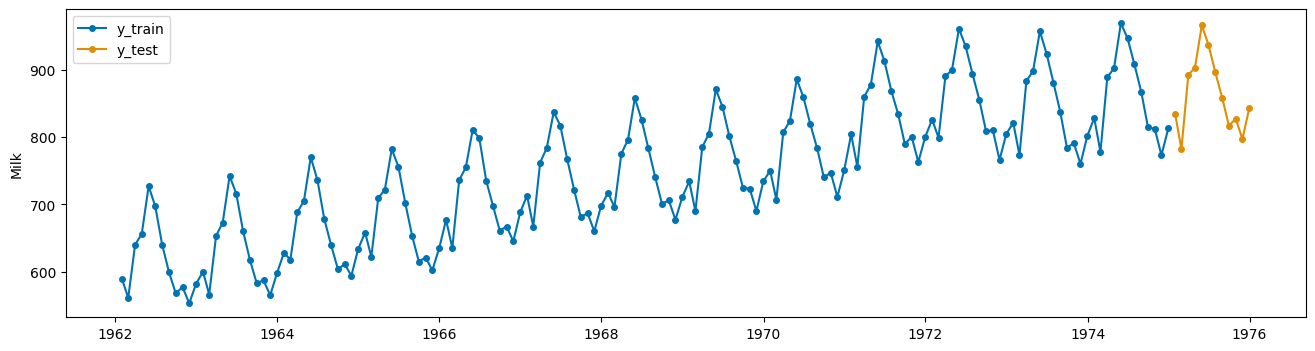

In [4]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv", index_col=0)
df.index = pd.date_range(start='1962-01-01', periods=len(df), freq='ME')
y = df['Milk']
y_train, y_test = temporal_train_test_split(y, test_size=12)
plot_series(y_train, y_test, labels=["y_train", 'y_test'])
plt.legend()
plt.show()

In [7]:
forecaster = AutoARIMA(sp=12, d=0, max_p=3, max_q=3, max_P=3, max_D=1,max_Q=3,suppress_warnings=True)
forecaster.fit(y_train)

AutoARIMA(d=0, max_P=3, max_Q=3, max_p=3, max_q=3, sp=12,
          suppress_warnings=True)

d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_al

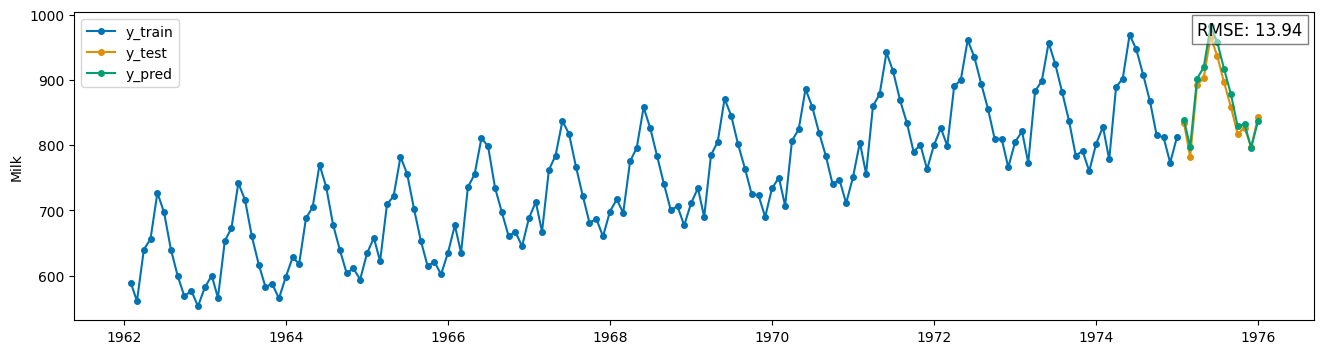

In [11]:
y_pred = forecaster.predict(fh=np.arange(1, len(y_test)+1))
rmse = MeanSquaredError(square_root=True)
plot_series(y_train,y_test,y_pred, labels=["y_train", "y_test", "y_pred"])
plt.text(y.index[-10], max(y), f'RMSE: {rmse(y_test, y_pred):.2f}', fontsize=12,bbox=dict(facecolor='white', alpha=0.5))
plt.legend()
plt.show()

#### Dataset - monthly-beer production

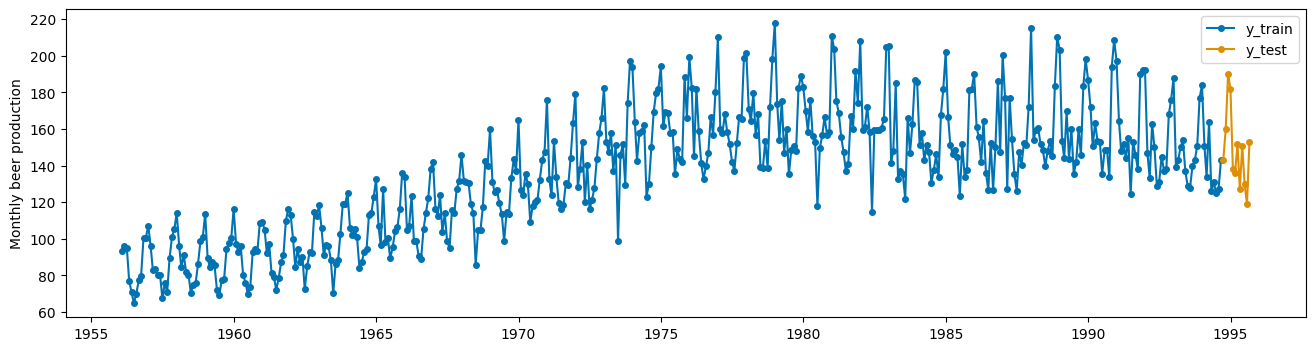

In [21]:
df = pd.read_csv("monthly-beer-production-in-austr.csv", index_col=0)
df.head()
df.index = pd.date_range(start='1956-01-01', periods=len(df), freq='ME')
y = df['Monthly beer production']
y_train, y_test = temporal_train_test_split(y, test_size=12)
plot_series(y_train, y_test, labels=["y_train", 'y_test'])
plt.legend()
plt.show()

In [22]:
forecaster = AutoARIMA(sp=12, d=0, max_p=3, max_q=3, max_P=3, max_D=1,max_Q=3,suppress_warnings=True)
forecaster.fit(y_train)

d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.w

AutoARIMA(d=0, max_P=3, max_Q=3, max_p=3, max_q=3, sp=12,
          suppress_warnings=True)

d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_al

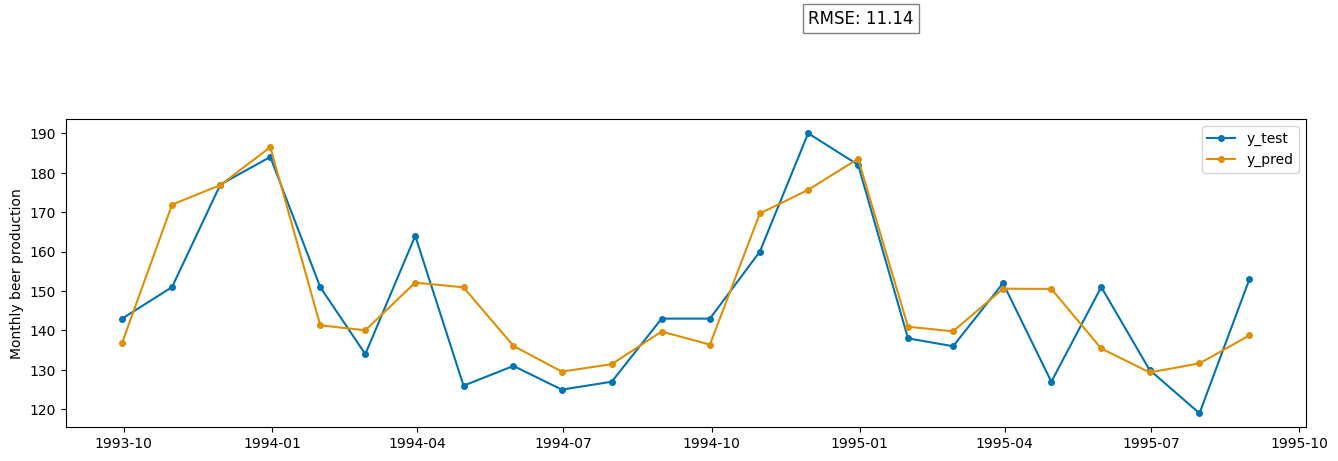

In [20]:
y_pred = forecaster.predict(fh=np.arange(1, len(y_test)+1))
rmse = MeanSquaredError(square_root=True)
plot_series(y_test,y_pred, labels=[ "y_test", "y_pred"])
plt.text(y.index[-10], max(y), f'RMSE: {rmse(y_test, y_pred):.2f}', fontsize=12,bbox=dict(facecolor='white', alpha=0.5))
plt.legend()
plt.show()